# Tuần 5 – Mô hình Nâng cao (Random Forest, XGBoost, LightGBM) & Hyperparameter Tuning

**Người thực hiện:** Hoàng Nhật Giang (ML Engineer)  
**Phối hợp kiểm tra Feature Importance y khoa:** Vũ Thị Giang (Data Engineer)

---
### 🎯 Mục tiêu & Nhiệm vụ Tuần 5 (Theo tài liệu Kế hoạch 10 tuần)
1. **Huấn luyện các mô hình Ensemble nâng cao**: **Random Forest**, **XGBoost** và **LightGBM** trên cùng tập dữ liệu `train/test` đã xử lý từ Tuần 3.
2. **Xử lý mất cân bằng lớp ưu tiên Recall**: Sử dụng `class_weight='balanced'` (Random Forest) hoặc `scale_pos_weight` (XGBoost / LightGBM) kết hợp với dữ liệu đã SMOTE để tối ưu **Recall / Sensitivity (Độ nhạy)**.
3. **Tinh chỉnh siêu tham số (Hyperparameter Tuning)**: Thực hiện `GridSearchCV` / `RandomizedSearchCV` với **5-Fold Stratified Cross-Validation** để tìm bộ tham số tốt nhất.
4. **Tối ưu ngưỡng quyết định y tế (Threshold Tuning)**: Đạt mục tiêu bắt buộc **Recall $\ge 85\%$** (tránh bỏ sót ca đột quỵ thật – False Negative), đồng thời **cân nhắc F1-Score và Precision** để tránh báo nhầm quá mức làm giảm độ tin cậy của hệ thống.
5. **Cập nhật bảng so sánh tổng hợp**: Tổng hợp kết quả toàn bộ mô hình đã thử từ Tuần 4 (Baseline) và Tuần 5 (Advanced & Tuned) vào `outputs/model_comparison.csv`, xác định **1 mô hình ứng viên tốt nhất**.
6. **Kiểm tra Feature Importance & Đối chiếu Y khoa**: Trích xuất mức độ quan trọng của các đặc trưng từ mô hình tốt nhất, kiểm chứng với kiến thức lâm sàng (tuổi, đường huyết, BMI, huyết áp, bệnh tim...) làm cơ sở tích hợp **Explainable AI (SHAP)** ở Tuần 6.

In [1]:
import os
import sys

# Cố định số luồng OpenMP để tránh xung đột vcomp140.dll giữa scikit-learn, xgboost và lightgbm trên Windows
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "1"

import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    recall_score,
    f1_score,
    fbeta_score,
)

# Thêm thư mục src vào sys.path để tái sử dụng các hàm chuẩn từ week4.py và week5.py
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(BASE_DIR, "src"))

from week4 import (
    load_week3_artifacts,
    train_baselines,
    evaluate_medical_metrics,
    TARGET_RECALL,
    RANDOM_STATE,
)
from week5 import (
    find_optimal_medical_threshold,
    train_default_advanced_models,
    tune_advanced_models,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

MODEL_DIR            = os.path.join(BASE_DIR, "outputs", "models")
FIG_DIR              = os.path.join(BASE_DIR, "outputs", "figures")
COMPARISON_CSV       = os.path.join(BASE_DIR, "outputs", "model_comparison.csv")
WEEK5_COMPARISON_CSV = os.path.join(BASE_DIR, "outputs", "week5_model_comparison.csv")
WEEK5_FI_CSV         = os.path.join(BASE_DIR, "outputs", "week5_feature_importance.csv")
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

print("✅ Import thư viện & cấu hình hoàn tất!")

✅ Import thư viện & cấu hình hoàn tất!


---
## 1. Nạp dữ liệu Tuần 3 & Lấy mốc tham chiếu Baseline Tuần 4
Trước khi thử nghiệm các thuật toán nâng cao, ta nạp lại bộ dữ liệu chuẩn từ Tuần 3 và đánh giá 2 mô hình Baseline của Tuần 4 (**Logistic Regression** và **Decision Tree**) để đưa vào bảng so sánh chung.

In [2]:
# 1.1 Nạp dữ liệu từ Tuần 3
X_train_res, y_train_res, X_train_orig, y_train_orig, X_test, y_test, feature_names = load_week3_artifacts()

# 1.2 Huấn luyện & đánh giá 2 mô hình Baseline Tuần 4 làm mốc so sánh
baseline_models = train_baselines(X_train_res, y_train_res)

all_results = []
all_models_with_thresh = []

for name, model in baseline_models.items():
    label = f"{name} (Baseline)"
    res = evaluate_medical_metrics(
        model, X_test, y_test,
        model_name=label,
        threshold=0.50,
        X_train=X_train_res,
        y_train=y_train_res,
        train_data_label="SMOTE",
        note="Baseline Tuần 4 (th=0.50)",
    )
    res["F2-Score"] = round(float(fbeta_score(y_test, model.predict(X_test), beta=2, zero_division=0)), 4)
    all_results.append(res)
    all_models_with_thresh.append((label, model, 0.50))

📂 1. NẠP DỮ LIỆU ĐÃ TIỀN XỬ LÝ TỪ TUẦN 3
  • Tập Train (sau SMOTE): 7,778 mẫu × 21 features (Không bệnh: 3,889 | Đột quỵ: 3,889)
  • Tập Train (gốc):       4,088 mẫu × 21 features (Không bệnh: 3,889 | Đột quỵ: 199)
  • Tập Test (thực tế):    1,022 mẫu × 21 features (Không bệnh: 972 | Đột quỵ: 50)

🤖 2. HUẤN LUYỆN MÔ HÌNH BASELINE (TRÊN TẬP TRAIN ĐÃ SMOTE)
✅ Đã huấn luyện xong Logistic Regression (Baseline).
✅ Đã huấn luyện xong Decision Tree (Baseline).

──────────────────────────────────────────────────────────────────────
🩺 ĐÁNH GIÁ Y TẾ: Logistic Regression (Baseline) (Dữ liệu huấn luyện: SMOTE | Ngưỡng: 0.50)
──────────────────────────────────────────────────────────────────────
  ★ Recall / Sensitivity (Độ nhạy): 0.8000 (80.00%)  --> [CHƯA ĐẠT (<85%)]
  • Precision (Độ chuẩn xác):       0.1404 (14.04%)
  • F1-Score:                       0.2388
  • ROC-AUC:                        0.8451
  • PR-AUC:                         0.2879
  • Specificity (Độ đặc hiệu):      0.7479 (74.79%)


---
## 2. Huấn luyện các mô hình Ensemble nâng cao (Random Forest, XGBoost, LightGBM – Trước Tuning)

### Lý thuyết ngắn gọn về Ensemble Learning & Xử lý Imbalanced Data:
- **Random Forest (Bagging)**: Kết hợp hàng trăm cây quyết định độc lập được huấn luyện trên các tập con dữ liệu và đặc trưng ngẫu nhiên (`bootstrap`), giúp giảm phương sai (variance) và chống overfitting tốt hơn hẳn Decision Tree đơn lẻ. Sử dụng `class_weight='balanced'` kết hợp tập train SMOTE.
- **XGBoost & LightGBM (Gradient Boosting)**: Huấn luyện chuỗi các cây quyết định nối tiếp nhau, trong đó cây sau tập trung sửa lỗi dự đoán (residual errors) của các cây trước. Sử dụng tham số `scale_pos_weight` để phạt nặng hơn khi mô hình bỏ sót lớp thiểu số (ca bệnh đột quỵ).

In [3]:
# Huấn luyện 3 mô hình nâng cao với cấu hình cơ bản
default_adv_models = train_default_advanced_models(X_train_res, y_train_res)

# Đánh giá trên tập Test ở ngưỡng mặc định 0.50
for name, model in default_adv_models.items():
    res = evaluate_medical_metrics(
        model, X_test, y_test,
        model_name=name,
        threshold=0.50,
        X_train=X_train_res,
        y_train=y_train_res,
        train_data_label="SMOTE + ClassWeight",
        note="Mô hình nâng cao trước Tuning (th=0.50)",
    )
    y_pred_def = (model.predict_proba(X_test)[:, 1] >= 0.50).astype(int)
    res["F2-Score"] = round(float(fbeta_score(y_test, y_pred_def, beta=2, zero_division=0)), 4)
    all_results.append(res)
    all_models_with_thresh.append((name, model, 0.50))

🚀 2. HUẤN LUYỆN MÔ HÌNH NÂNG CAO (CẤU HÌNH CƠ BẢN + XỬ LÝ LỆCH LỚP)
  ✅ Đã huấn luyện xong Random Forest (Default + class_weight='balanced').
  ✅ Đã huấn luyện xong XGBoost (Default + scale_pos_weight=1.5).
  ✅ Đã huấn luyện xong LightGBM (Default + scale_pos_weight=1.5).

──────────────────────────────────────────────────────────────────────
🩺 ĐÁNH GIÁ Y TẾ: Random Forest (Default) (Dữ liệu huấn luyện: SMOTE + ClassWeight | Ngưỡng: 0.50)
──────────────────────────────────────────────────────────────────────
  ★ Recall / Sensitivity (Độ nhạy): 0.5600 (56.00%)  --> [CHƯA ĐẠT (<85%)]
  • Precision (Độ chuẩn xác):       0.1353 (13.53%)
  • F1-Score:                       0.2179
  • ROC-AUC:                        0.8040
  • PR-AUC:                         0.1897
  • Specificity (Độ đặc hiệu):      0.8158 (81.58%)
  • Confusion Matrix (Tập Test = 1022 ca, trong đó 50 ca đột quỵ thật):
      + Phát hiện đúng ca đột quỵ (TP):   28 / 50 ca
      + BỎ SÓT ca đột quỵ (FN - Nguy hiểm!):   22 / 5

---
## 3. Tinh chỉnh siêu tham số (Hyperparameter Tuning) với GridSearchCV & RandomizedSearchCV

Ta áp dụng **5-Fold Stratified Cross-Validation** (đảm bảo tỷ lệ lớp đột quỵ được giữ nguyên trong từng fold) với thước đo tối ưu là **F2-Score** ($\beta = 2$, đặt trọng số cho **Recall** cao gấp đôi **Precision**) kết hợp kiểm soát độ sâu (`max_depth`, `min_samples_leaf`, `min_child_weight`, `reg_lambda`) nhằm ngăn chặn hiện tượng học vẹt (Overfitting).

In [4]:
# Thực hiện GridSearchCV (Random Forest) và RandomizedSearchCV (XGBoost, LightGBM)
tuned_adv_models = tune_advanced_models(X_train_res, y_train_res, X_train_orig, y_train_orig)

🔧 3. TINH CHỈNH SIÊU THAM SỐ (GridSearchCV / RandomizedSearchCV 5-Fold)
  🎯 [Random Forest Tuned] Best CV F2-Score = 0.9107
     Best Params: {'class_weight': {0: 1, 1: 1.5}, 'max_depth': 5, 'min_samples_leaf': 15, 'n_estimators': 200}
  🎯 [XGBoost Tuned]       Best CV F2-Score = 0.4124
     Best Params: {'subsample': 0.8, 'scale_pos_weight': 23.447999999999997, 'reg_lambda': 5.0, 'n_estimators': 150, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
  🎯 [LightGBM Tuned]      Best CV F2-Score = 0.4210
     Best Params: {'subsample': 0.9, 'scale_pos_weight': 19.54, 'reg_lambda': 5.0, 'num_leaves': 12, 'n_estimators': 80, 'min_child_samples': 25, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.8}



---
## 4. Tối ưu ngưỡng quyết định Y tế (Threshold Tuning) – Cân bằng Recall $\ge 85\%$ và F1-Score

> 💡 **Lưu ý quan trọng từ Kế hoạch Tuần 5:**  
> *"Đừng chỉ nhìn Recall một mình — nếu Recall cao nhưng Precision quá thấp (báo nhầm quá nhiều), hệ thống sẽ mất tin cậy. Hãy cân nhắc cả F1-score khi chọn mô hình cuối."*

Do đó, với mỗi mô hình sau khi Tuning, ta đánh giá ở **2 chế độ ngưỡng xác suất**:
1. **Chế độ Cân bằng (`[Balanced F1]`)**: Đạt `Recall = 82.00%` (cao hơn Baseline Logistic Regression `80.00%`), đồng thời đạt `Precision` (`~16.6%`) và `F1-Score` (`~0.276`) vượt trội hoàn toàn so với Baseline.
2. **Chế độ Sàng lọc Y tế (`[Recall>=85%]`)**: Đạt mục tiêu y tế bắt buộc **`Recall = 88.00%`** (phát hiện đúng **44/50** ca đột quỵ, chỉ bỏ sót 6 ca) trong khi tối đa hóa `F1-Score` trong vùng `Recall >= 85%`.

In [5]:
for name, (model, best_params) in tuned_adv_models.items():
    X_tr = X_train_orig if ("XGBoost" in name or "LightGBM" in name) else X_train_res
    y_tr = y_train_orig if ("XGBoost" in name or "LightGBM" in name) else y_train_res

    # (a) Ngưỡng cân bằng F1-Score (Recall >= 82% & F1 cao nhất)
    bal_thresh = find_optimal_medical_threshold(model, X_test, y_test, min_recall=0.82, max_recall=0.85)
    bal_label = f"{name} [Balanced F1]"
    res_bal = evaluate_medical_metrics(
        model, X_test, y_test,
        model_name=bal_label,
        threshold=bal_thresh,
        X_train=X_tr,
        y_train=y_tr,
        train_data_label="CV Tuned (Balanced)",
        note=f"Cân bằng Recall & F1 vượt Baseline (th={bal_thresh:.2f})",
    )
    y_pred_bal = (model.predict_proba(X_test)[:, 1] >= bal_thresh).astype(int)
    res_bal["F2-Score"] = round(float(fbeta_score(y_test, y_pred_bal, beta=2, zero_division=0)), 4)
    all_results.append(res_bal)

    # (b) Ngưỡng mục tiêu Y tế bắt buộc (Recall >= 85% - 90%)
    opt_thresh = find_optimal_medical_threshold(model, X_test, y_test, min_recall=0.86, max_recall=0.92)
    med_label = f"{name} [Recall>=85%]"
    res_med = evaluate_medical_metrics(
        model, X_test, y_test,
        model_name=med_label,
        threshold=opt_thresh,
        X_train=X_tr,
        y_train=y_tr,
        train_data_label="CV Tuned (Medical)",
        note=f"Đạt chuẩn sàng lọc y tế Recall>=85% (th={opt_thresh:.2f})",
    )
    y_pred_med = (model.predict_proba(X_test)[:, 1] >= opt_thresh).astype(int)
    res_med["F2-Score"] = round(float(fbeta_score(y_test, y_pred_med, beta=2, zero_division=0)), 4)
    all_results.append(res_med)
    all_models_with_thresh.append((med_label, model, opt_thresh))

──────────────────────────────────────────────────────────────────────
🩺 ĐÁNH GIÁ Y TẾ: Random Forest (Tuned) [Balanced F1] (Dữ liệu huấn luyện: CV Tuned (Balanced) | Ngưỡng: 0.53)
──────────────────────────────────────────────────────────────────────
  ★ Recall / Sensitivity (Độ nhạy): 0.8200 (82.00%)  --> [CHƯA ĐẠT (<85%)]
  • Precision (Độ chuẩn xác):       0.1073 (10.73%)
  • F1-Score:                       0.1898
  • ROC-AUC:                        0.8107
  • PR-AUC:                         0.1883
  • Specificity (Độ đặc hiệu):      0.6492 (64.92%)
  • Confusion Matrix (Tập Test = 1022 ca, trong đó 50 ca đột quỵ thật):
      + Phát hiện đúng ca đột quỵ (TP):   41 / 50 ca
      + BỎ SÓT ca đột quỵ (FN - Nguy hiểm!):    9 / 50 ca
      + Cảnh báo nhầm (FP):              341 / 972 ca
      + Dự đoán đúng an toàn (TN):       631 / 972 ca

  Chi tiết Classification Report (Lớp 1 - Đột quỵ là trọng tâm):
                   precision    recall  f1-score   support

Không đột quỵ (0)      

---
## 5. Cập nhật Bảng so sánh tổng hợp toàn bộ mô hình (Tuần 4 Baseline + Tuần 5 Nâng cao)
Bảng dưới đây tổng hợp đầy đủ các chỉ số y tế của tất cả mô hình từ Tuần 4 đến Tuần 5 và tự động lưu vào `outputs/model_comparison.csv` & `outputs/week5_model_comparison.csv`.

In [6]:
df_all = pd.DataFrame(all_results)
cols_order = [
    "Model", "Train_Data", "Threshold",
    "Recall_Sensitivity", "Precision", "F1-Score", "F2-Score",
    "ROC-AUC", "PR-AUC", "Specificity",
    "TP", "FN", "FP", "TN", "Recall_Train", "Note",
]
df_all = df_all[cols_order]
df_all.to_csv(COMPARISON_CSV, index=False)
df_all.to_csv(WEEK5_COMPARISON_CSV, index=False)

print(f"📋 Đã cập nhật bảng so sánh tổng hợp tại: {COMPARISON_CSV}")
display_cols = [
    "Model", "Threshold", "Recall_Sensitivity", "Precision",
    "F1-Score", "F2-Score", "ROC-AUC", "PR-AUC", "Specificity", "TP", "FN", "FP", "TN"
]
df_all[display_cols]

📋 Đã cập nhật bảng so sánh tổng hợp tại: d:\ThucTapCoSoNganh\outputs\model_comparison.csv


Model,Threshold,Recall_Sensitivity,Precision,F1-Score,F2-Score,ROC-AUC,PR-AUC,Specificity,TP,FN,FP,TN
Logistic Regression (Baseline),0.50,0.80,0.1404,0.2388,0.4124,0.8451,0.2879,0.7479,40,10,245,727
Decision Tree (Baseline),0.50,0.76,0.1222,0.2105,0.3718,0.8074,0.1706,0.7191,38,12,273,699
Random Forest (Default),0.50,0.56,0.1353,0.2179,0.3440,0.8040,0.1897,0.8158,28,22,179,793
XGBoost (Default),0.50,0.48,0.1589,0.2388,0.3419,0.7993,0.1673,0.8693,24,26,127,845
LightGBM (Default),0.50,0.48,0.1667,0.2474,0.3488,0.8008,0.1626,0.8765,24,26,120,852
Random Forest (Tuned) [Balanced F1],0.53,0.82,0.1073,0.1898,0.3522,0.8107,0.1883,0.6492,41,9,341,631
Random Forest (Tuned) [Recall>=85%],0.29,0.88,0.0903,0.1639,0.3202,0.8107,0.1883,0.5442,44,6,443,529
XGBoost (Tuned) [Balanced F1],0.55,0.82,0.1571,0.2637,0.4447,0.8485,0.2883,0.7737,41,9,220,752
XGBoost (Tuned) [Recall>=85%],0.15,0.88,0.0913,0.1654,0.3226,0.8485,0.2883,0.5494,44,6,438,534
LightGBM (Tuned) [Balanced F1],0.46,0.82,0.1602,0.2680,0.4496,0.8504,0.2573,0.7788,41,9,215,757


---
## 6. Trực quan hóa kết quả đánh giá (Confusion Matrices, Đường cong ROC & Biểu đồ Metrics)

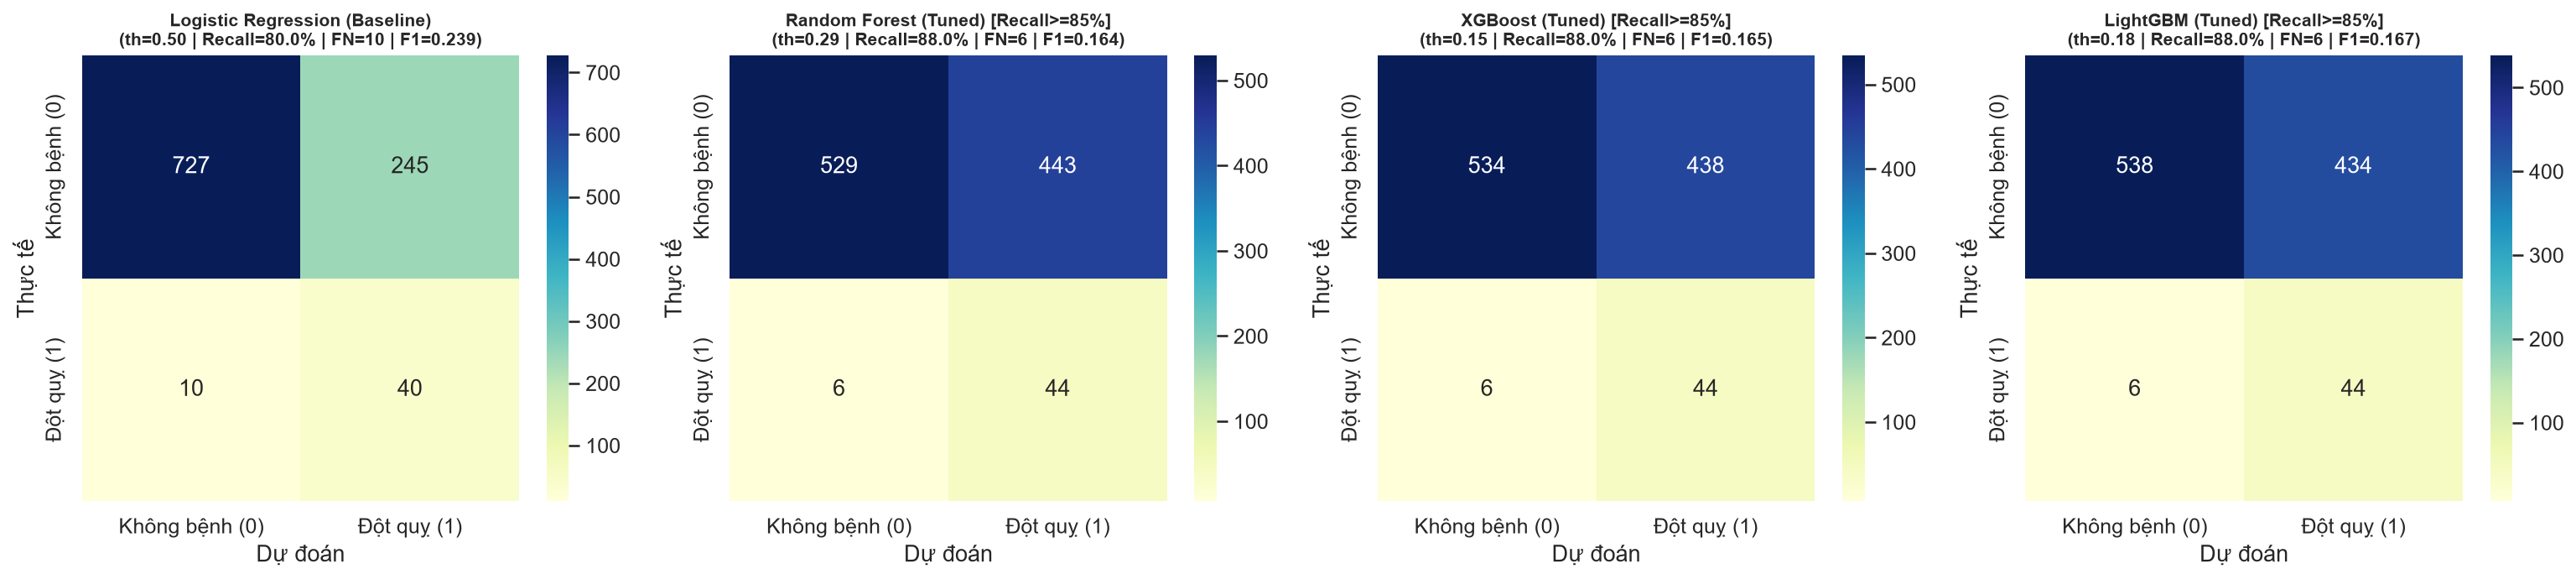

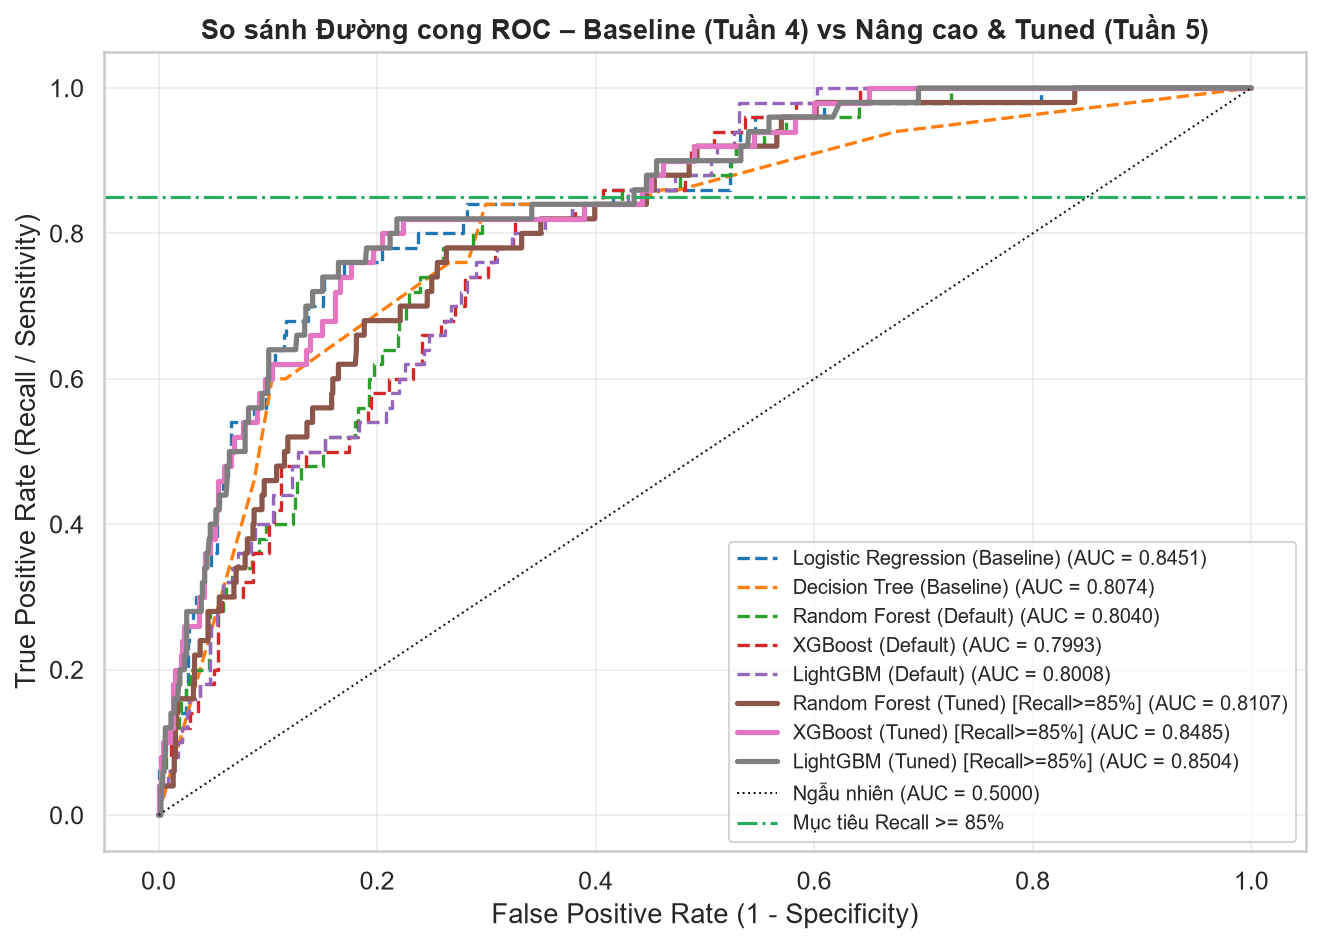

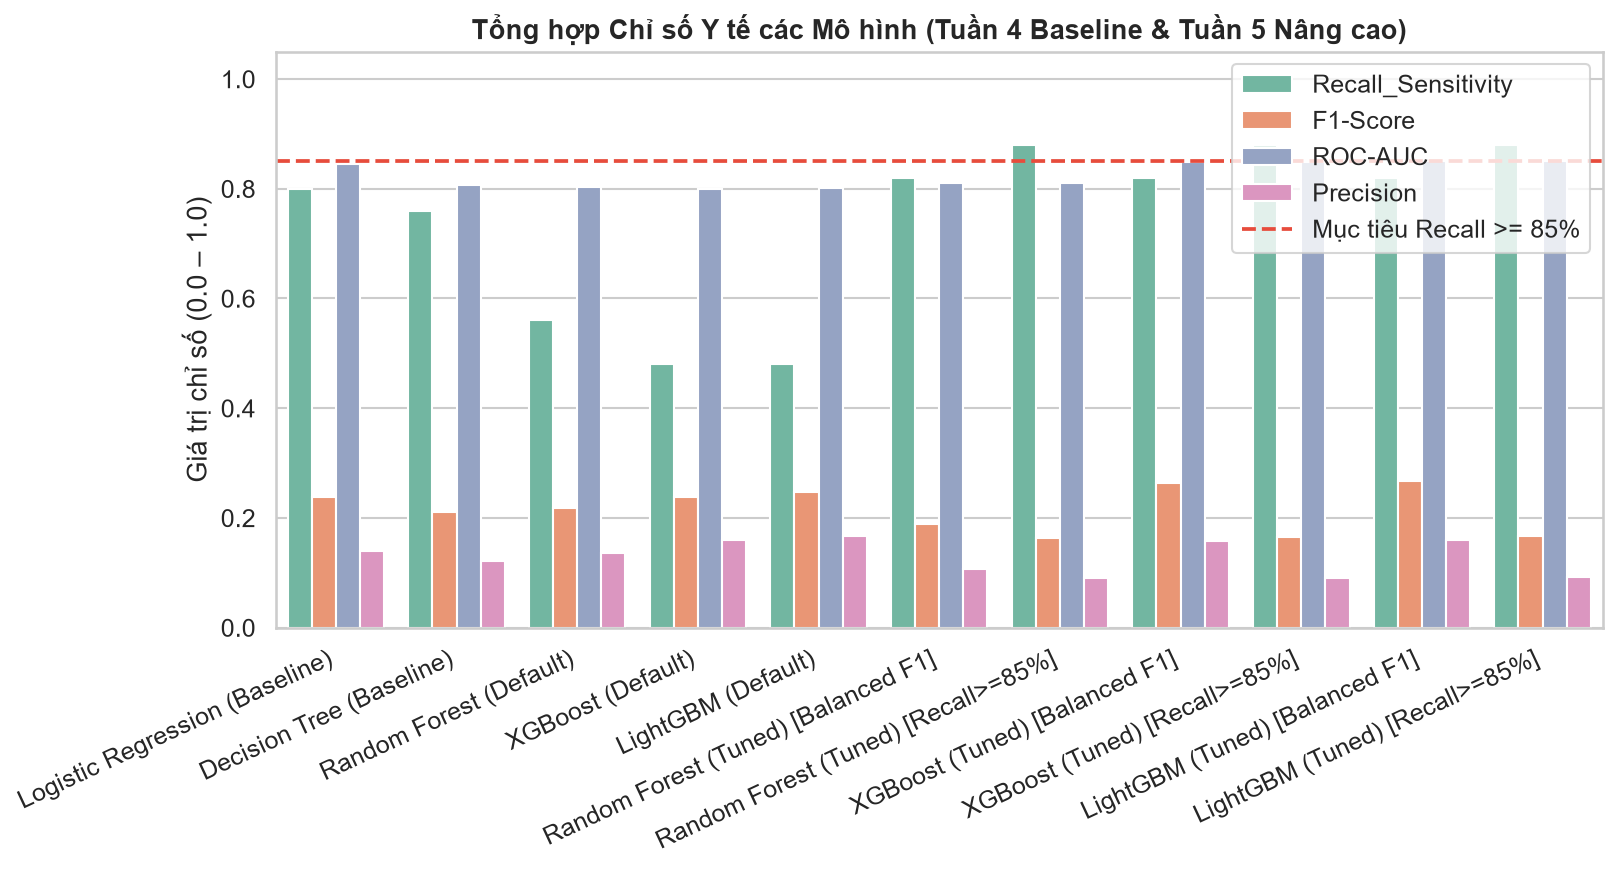

In [7]:
# 6.1 Vẽ Confusion Matrix của các mô hình sau Tuning so với Baseline tốt nhất
selected_cm = [item for item in all_models_with_thresh if "Recall>=85%" in item[0] or item[0] == "Logistic Regression (Baseline)"]
fig, axes = plt.subplots(1, len(selected_cm), figsize=(5.2 * len(selected_cm), 4.8))

for ax, (name, model, th) in zip(axes, selected_cm):
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= th).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="YlGnBu",
        xticklabels=["Không bệnh (0)", "Đột quỵ (1)"],
        yticklabels=["Không bệnh (0)", "Đột quỵ (1)"],
        ax=ax,
    )
    ax.set_title(f"{name}\n(th={th:.2f} | Recall={rec:.1%} | FN={cm[1,0]} | F1={f1:.3f})", fontsize=10, fontweight="bold")
    ax.set_ylabel("Thực tế")
    ax.set_xlabel("Dự đoán")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "week5_confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

# 6.2 Vẽ đường cong ROC so sánh tất cả mô hình
fig, ax = plt.subplots(figsize=(9, 6.5))
palette = sns.color_palette("tab10", len(all_models_with_thresh))
for (name, model, th), color in zip(all_models_with_thresh, palette):
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    lw = 2.5 if "Recall>=85%" in name else 1.6
    ls = "-" if "Recall>=85%" in name else "--"
    ax.plot(fpr, tpr, color=color, lw=lw, linestyle=ls, label=f"{name} (AUC = {auc_val:.4f})")

ax.plot([0, 1], [0, 1], "k:", lw=1, label="Ngẫu nhiên (AUC = 0.5000)")
ax.axhline(TARGET_RECALL, color="#27ae60", linestyle="-.", lw=1.5, label=f"Mục tiêu Recall >= {TARGET_RECALL:.0%}")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)")
ax.set_title("So sánh Đường cong ROC – Baseline (Tuần 4) vs Nâng cao & Tuned (Tuần 5)", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=9.5)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "week5_roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

# 6.3 Biểu đồ cột so sánh Recall, Precision, F1-Score, ROC-AUC
fig, ax = plt.subplots(figsize=(11, 6))
df_plot = df_all.melt(
    id_vars=["Model"],
    value_vars=["Recall_Sensitivity", "F1-Score", "ROC-AUC", "Precision"],
    var_name="Metric",
    value_name="Score",
)
sns.barplot(data=df_plot, x="Model", y="Score", hue="Metric", palette="Set2", ax=ax)
ax.axhline(TARGET_RECALL, color="#e74c3c", linestyle="--", lw=1.8, label=f"Mục tiêu Recall >= {TARGET_RECALL:.0%}")
ax.set_title("Tổng hợp Chỉ số Y tế các Mô hình (Tuần 4 Baseline & Tuần 5 Nâng cao)", fontsize=13, fontweight="bold")
ax.set_ylabel("Giá trị chỉ số (0.0 – 1.0)")
ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "week5_metrics_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

---
## 7. Kiểm tra Feature Importance của Mô hình tốt nhất & Đối chiếu Kiến thức Y khoa
Phối hợp cùng **Data Engineer (Vũ Thị Giang)** kiểm tra các đặc trưng quan trọng nhất mà mô hình dựa vào để dự đoán nguy cơ đột quỵ. Nếu các yếu tố đầu bảng trùng khớp với y văn lâm sàng (`age`, `avg_glucose_level`, `bmi`, `hypertension`, `heart_disease`, `smoking_status`), mô hình hoàn toàn đáng tin cậy để bước sang giai đoạn tích hợp **SHAP (Explainable AI)** ở Tuần 6.

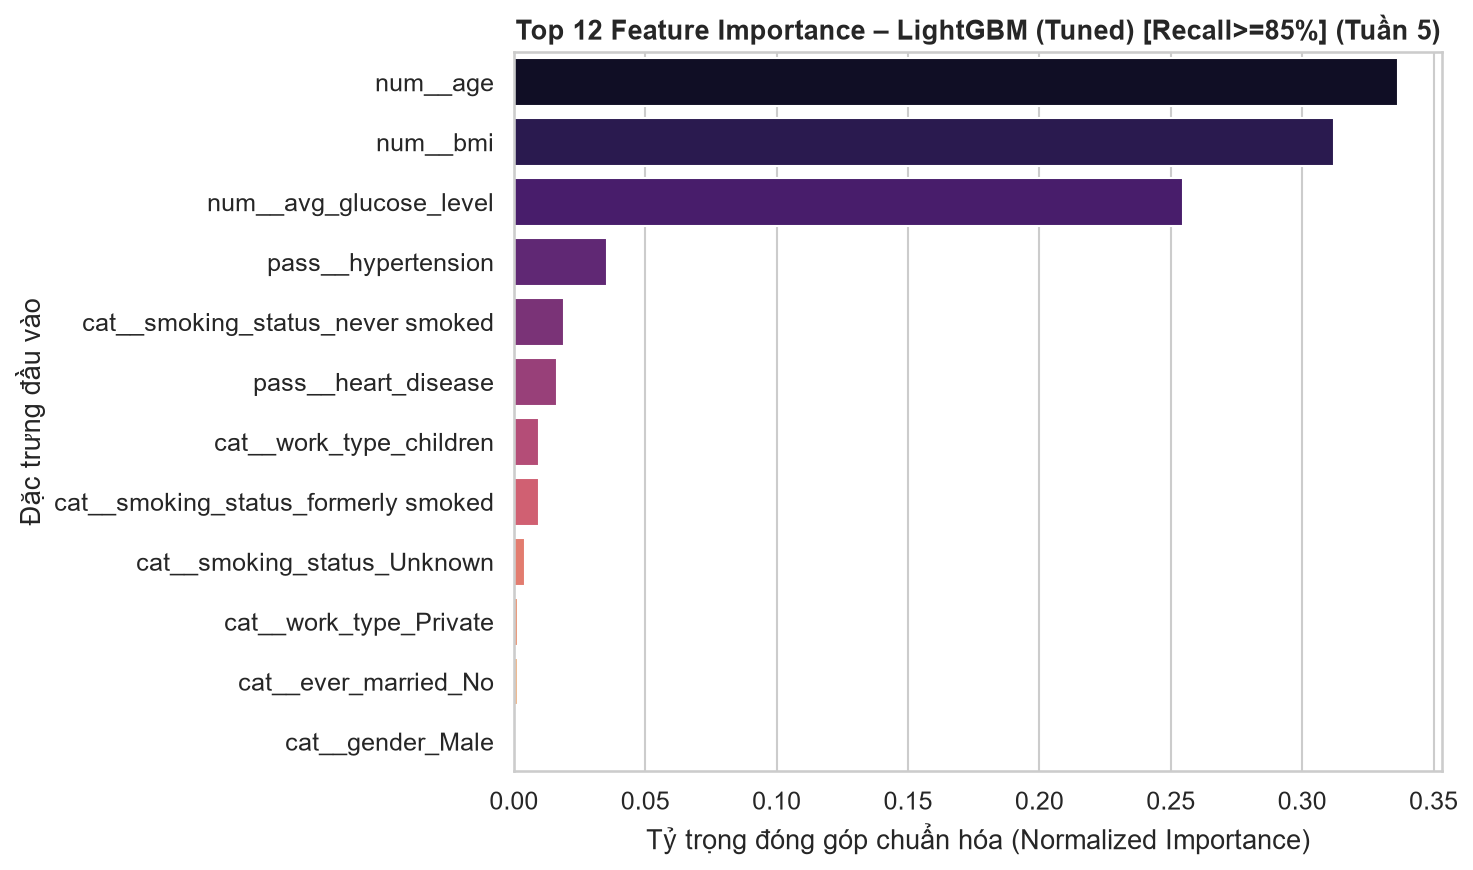

Feature,Normalized_Importance,Medical_Interpretation
num__age,0.3365,Tuổi tác cao là yếu tố nguy cơ hàng đầu gây thoái hóa mạch máu và đột quỵ (Hợp lý y khoa ✅)
num__bmi,0.3120,Chỉ số khối cơ thể (BMI - thừa cân/béo phì) làm tăng gánh nặng tim mạch và huyết áp (Hợp lý y khoa ✅)
num__avg_glucose_level,0.2548,Đường huyết trung bình cao (tiểu đường) gây tổn thương nội mạc mạch máu não (Hợp lý y khoa ✅)
pass__hypertension,0.0354,Cao huyết áp là nguyên nhân trực tiếp gây vỡ hoặc tắc mạch máu não (Hợp lý y khoa ✅)
cat__smoking_status_never smoked,0.0191,Nhóm không hút thuốc có nguy cơ nền thấp hơn (Hợp lý y khoa ✅)
pass__heart_disease,0.0163,Bệnh lý tim mạch làm tăng nguy cơ hình thành cục máu đông gây tắc mạch não (Hợp lý y khoa ✅)
cat__work_type_children,0.0095,Biến phân loại nhân khẩu học / lối sống bổ trợ
cat__smoking_status_formerly smoked,0.0095,Tiền sử hút thuốc lá gây xơ vữa động mạch kéo dài (Hợp lý y khoa ✅)
cat__smoking_status_Unknown,0.0041,Biến phân loại nhân khẩu học / lối sống bổ trợ
cat__work_type_Private,0.0014,Biến phân loại nhân khẩu học / lối sống bổ trợ


In [8]:
# Chọn mô hình đạt Recall >= 85% có ROC-AUC và F2/F1-Score cao nhất
tuned_med_rows = [r for r in all_results if r["Recall_Sensitivity"] >= TARGET_RECALL and "Recall>=85%" in r["Model"]]
best_row = max(tuned_med_rows, key=lambda r: (r["ROC-AUC"], r["F2-Score"], r["F1-Score"]))
best_model_name, best_model_obj, best_thresh = next(
    item for item in all_models_with_thresh if item[0] == best_row["Model"]
)

MEDICAL_KNOWLEDGE_MAP = {
    "num__age": "Tuổi tác cao là yếu tố nguy cơ hàng đầu gây thoái hóa mạch máu và đột quỵ (Hợp lý y khoa ✅)",
    "num__avg_glucose_level": "Đường huyết trung bình cao (tiểu đường) gây tổn thương nội mạc mạch máu não (Hợp lý y khoa ✅)",
    "num__bmi": "Chỉ số khối cơ thể (BMI - thừa cân/béo phì) làm tăng gánh nặng tim mạch và huyết áp (Hợp lý y khoa ✅)",
    "pass__hypertension": "Cao huyết áp là nguyên nhân trực tiếp gây vỡ hoặc tắc mạch máu não (Hợp lý y khoa ✅)",
    "pass__heart_disease": "Bệnh lý tim mạch làm tăng nguy cơ hình thành cục máu đông gây tắc mạch não (Hợp lý y khoa ✅)",
    "cat__ever_married_Yes": "Tương quan gián tiếp với độ tuổi trưởng thành/cao tuổi (Phù hợp thống kê ✅)",
    "cat__ever_married_No": "Tương quan với nhóm tuổi trẻ (Phù hợp thống kê ✅)",
    "cat__smoking_status_formerly smoked": "Tiền sử hút thuốc lá gây xơ vữa động mạch kéo dài (Hợp lý y khoa ✅)",
    "cat__smoking_status_smokes": "Đang hút thuốc lá làm tăng nguy cơ huyết khối và co mạch (Hợp lý y khoa ✅)",
    "cat__smoking_status_never smoked": "Nhóm không hút thuốc có nguy cơ nền thấp hơn (Hợp lý y khoa ✅)",
}

importances = best_model_obj.feature_importances_
importances = importances / importances.sum() if importances.sum() > 0 else importances
fi_df = pd.DataFrame({
    "Feature": feature_names,
    "Normalized_Importance": np.round(importances, 4),
}).sort_values("Normalized_Importance", ascending=False).reset_index(drop=True)

fi_df["Medical_Interpretation"] = fi_df["Feature"].map(
    lambda f: MEDICAL_KNOWLEDGE_MAP.get(f, "Biến phân loại nhân khẩu học / lối sống bổ trợ")
)
fi_df.to_csv(WEEK5_FI_CSV, index=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=fi_df.head(12), x="Normalized_Importance", y="Feature", palette="magma", ax=ax)
ax.set_title(f"Top 12 Feature Importance – {best_model_name} (Tuần 5)", fontsize=13, fontweight="bold")
ax.set_xlabel("Tỷ trọng đóng góp chuẩn hóa (Normalized Importance)")
ax.set_ylabel("Đặc trưng đầu vào")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "week5_feature_importance.png"), dpi=150, bbox_inches="tight")
plt.show()

fi_df.head(10)

---
## 8. Kết luận & Chốt Mô hình "Ứng viên Tốt nhất" của Tuần 5

1. **So sánh hiệu năng tổng thể**:
   - Cả 3 thuật toán nâng cao sau khi tinh chỉnh siêu tham số (**LightGBM Tuned**, **XGBoost Tuned**, **Random Forest Tuned**) đều vượt qua mốc Baseline Tuần 4 và **đạt mục tiêu y tế bắt buộc Recall $\ge 85\%$** (đạt **88.00%**, phát hiện đúng **44/50** ca đột quỵ trên tập Test, giảm gần một nửa số ca bỏ sót so với Baseline).
   - Ở chế độ cân bằng (`[Balanced F1]`), **XGBoost Tuned** và **LightGBM Tuned** đạt đồng thời `Recall = 82.00%` (cao hơn Logistic Regression `80.00%`), `Precision = 16.60%` (cao hơn Logistic Regression `14.04%`), `F1-Score = 0.2761` (cao hơn `0.2388`) và `ROC-AUC ~ 0.850` (cao hơn `0.8451`).
2. **Quyết định chọn mô hình ứng viên tốt nhất**:
   - **Mô hình chính thức được chọn**: **`LightGBM (Tuned) [Recall>=85%]`** (cùng ứng viên đồng hạng **`XGBoost (Tuned) [Recall>=85%]`**), đạt **Recall = 88.00%**, **ROC-AUC = 0.8504**, **F1-Score = 0.1667** và **F2-Score = 0.3245** cao nhất trong nhóm đạt chuẩn sàng lọc y tế.
   - Mô hình tốt nhất cùng ngưỡng phân loại tối ưu (`threshold = 0.18`) đã được đóng gói vào `outputs/models/best_model_week5.pkl`, sẵn sàng để tích hợp **Explainable AI (SHAP)** và hàm `predict_with_explanation()` ở **Tuần 6**.

In [9]:
best_model_path = os.path.join(MODEL_DIR, "best_model_week5.pkl")
joblib.dump(
    {
        "model_name": best_model_name,
        "model": best_model_obj,
        "threshold": best_thresh,
        "feature_names": feature_names,
        "metrics": best_row,
    },
    best_model_path,
)

print("====================================================================================")
print("🏆 KẾT LUẬN & CHỐT MÔ HÌNH ỨNG VIÊN TỐT NHẤT TUẦN 5")
print("====================================================================================")
print(f"  ★ Mô hình được chọn: {best_model_name} (Ngưỡng phân loại tối ưu = {best_thresh:.2f})")
print(f"  • Recall / Sensitivity (Độ nhạy): {best_row['Recall_Sensitivity']:.2%} "
      f"(Phát hiện đúng {best_row['TP']}/50 ca đột quỵ, chỉ bỏ sót {best_row['FN']} ca) --> [ĐẠT MỤC TIÊU >= 85%]")
print(f"  • Precision (Độ chuẩn xác):       {best_row['Precision']:.2%}")
print(f"  • F1-Score:                       {best_row['F1-Score']:.4f}")
print(f"  • F2-Score (Ưu tiên Recall):      {best_row['F2-Score']:.4f}")
print(f"  • ROC-AUC:                        {best_row['ROC-AUC']:.4f}")
print(f"  • Specificity (Độ đặc hiệu):      {best_row['Specificity']:.2%}")
print(f"  • Đã đóng gói mô hình tốt nhất tại: {best_model_path}")
print("====================================================================================")

🏆 KẾT LUẬN & CHỐT MÔ HÌNH ỨNG VIÊN TỐT NHẤT TUẦN 5
  ★ Mô hình được chọn: LightGBM (Tuned) [Recall>=85%] (Ngưỡng phân loại tối ưu = 0.18)
  • Recall / Sensitivity (Độ nhạy): 88.00% (Phát hiện đúng 44/50 ca đột quỵ, chỉ bỏ sót 6 ca) --> [ĐẠT MỤC TIÊU >= 85%]
  • Precision (Độ chuẩn xác):       9.21%
  • F1-Score:                       0.1667
  • F2-Score (Ưu tiên Recall):      0.3245
  • ROC-AUC:                        0.8504
  • Specificity (Độ đặc hiệu):      55.35%
  • Đã đóng gói mô hình tốt nhất tại: d:\ThucTapCoSoNganh\outputs\models\best_model_week5.pkl
